# 2. Plotting heatmaps of doublet scores, by leiden cluster, to filter for low quality clusters

#### Import modules

In [1]:
import os, sys
import scanpy as sc

from pathlib import Path
_p = Path(".").resolve()
while not (_p / "src" / "config.py").exists() and _p != _p.parent:
    _p = _p.parent
sys.path.insert(0, str(_p))
from src.config import ANALYSIS_DIR, DATA_DIR


#### Make our source code available to the python interpreter

In [2]:
from src.vis import plot_cluster_doublets
from src.vis import save_doublet_umaps


In [3]:
os.getcwd()

'/Users/stanleydale/user_generated/breault-lab/single-cell/data'

In [5]:
d2_dz_clustered = sc.read_h5ad(ANALYSIS_DIR / "data-objects/clustered/clustered_egfDuod_D2_DZ.h5ad")

In [6]:
d2_dz_qc = sc.read(ANALYSIS_DIR / "data-objects/qc/doublet_egfDuod_D2_DZ.h5ad")

In [7]:
## Transfer our doublet labels

d2_dz_clustered.obs["doublet_score"] = d2_dz_qc.obs["doublet_score"]
d2_dz_clustered.obs["predicted_doublet"] = d2_dz_qc.obs["predicted_doublet"]

In [8]:
## Double check our metadata

(d2_dz_clustered.obs["doublet_score"].head(), d2_dz_clustered.obs["predicted_doublet"].value_counts())


(AAACCAAAGATACTCG-1    0.027732
 AAACCAAAGCCAACTA-1    0.123077
 AAACCAAAGGCACACT-1    0.041555
 AAACCAAAGGTGCTCG-1    0.128277
 AAACCAAAGTCAACTG-1    0.107331
 Name: doublet_score, dtype: float64,
 predicted_doublet
 False    46210
 Name: count, dtype: int64)

In [9]:
(d2_dz_qc.obs["doublet_score"].head(), d2_dz_qc.obs["predicted_doublet"].value_counts())


(AAACCAAAGATACTCG-1    0.027732
 AAACCAAAGCCAACTA-1    0.123077
 AAACCAAAGGCACACT-1    0.041555
 AAACCAAAGGTGCTCG-1    0.128277
 AAACCAAAGTCAACTG-1    0.107331
 Name: doublet_score, dtype: float64,
 predicted_doublet
 False    46210
 Name: count, dtype: int64)

## Let's plot the clusters themselves on our different representations first

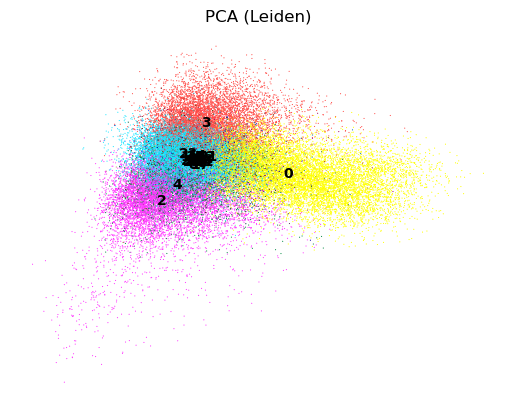

In [13]:
# 1) Ensure categorical
d2_dz_clustered.obs['leiden'] = d2_dz_clustered.obs['leiden'].astype('category')

# 2) Clear any cached colors for this key
if 'leiden_colors' in d2_dz_clustered.uns:
    del d2_dz_clustered.uns['leiden_colors']

# 3) Replot with an explicit palette
sc.pl.pca(
    d2_dz_clustered,
    color='leiden',
    palette=sc.pl.palettes.default_102,  # or sc.pl.palettes.zeileis_28
    legend_loc='on data',
    frameon=False,
    title='PCA (Leiden)',
)

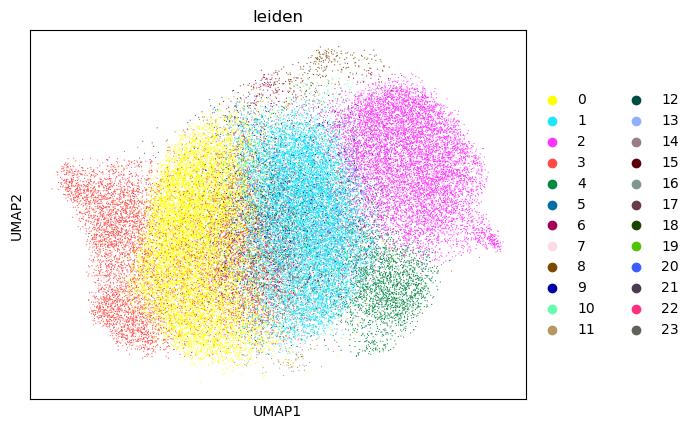

In [14]:
sc.pl.umap(d2_dz_clustered, color = 'leiden')

## Plot the doublet heatmaps, by Cluster

In [16]:
list(d2_dz_clustered.obs['leiden'])

['11',
 '2',
 '2',
 '4',
 '5',
 '0',
 '2',
 '0',
 '1',
 '0',
 '0',
 '3',
 '15',
 '0',
 '4',
 '2',
 '3',
 '1',
 '1',
 '0',
 '3',
 '5',
 '4',
 '1',
 '22',
 '2',
 '3',
 '6',
 '0',
 '0',
 '1',
 '0',
 '0',
 '2',
 '0',
 '2',
 '0',
 '0',
 '0',
 '0',
 '2',
 '0',
 '0',
 '0',
 '2',
 '3',
 '1',
 '4',
 '3',
 '2',
 '1',
 '0',
 '1',
 '0',
 '0',
 '2',
 '2',
 '3',
 '19',
 '0',
 '3',
 '0',
 '5',
 '1',
 '2',
 '3',
 '0',
 '0',
 '1',
 '0',
 '3',
 '2',
 '0',
 '0',
 '8',
 '2',
 '2',
 '3',
 '11',
 '3',
 '9',
 '8',
 '0',
 '3',
 '1',
 '0',
 '1',
 '0',
 '4',
 '2',
 '1',
 '2',
 '9',
 '1',
 '2',
 '0',
 '0',
 '0',
 '0',
 '2',
 '0',
 '3',
 '3',
 '17',
 '2',
 '0',
 '1',
 '0',
 '1',
 '0',
 '1',
 '1',
 '1',
 '5',
 '0',
 '3',
 '0',
 '3',
 '2',
 '1',
 '1',
 '0',
 '0',
 '4',
 '0',
 '0',
 '0',
 '4',
 '18',
 '0',
 '0',
 '1',
 '2',
 '7',
 '1',
 '1',
 '2',
 '2',
 '0',
 '2',
 '4',
 '0',
 '0',
 '2',
 '2',
 '3',
 '1',
 '0',
 '2',
 '0',
 '1',
 '1',
 '1',
 '13',
 '0',
 '0',
 '2',
 '2',
 '2',
 '0',
 '15',
 '1',
 '2',
 '1',
 '2',
 

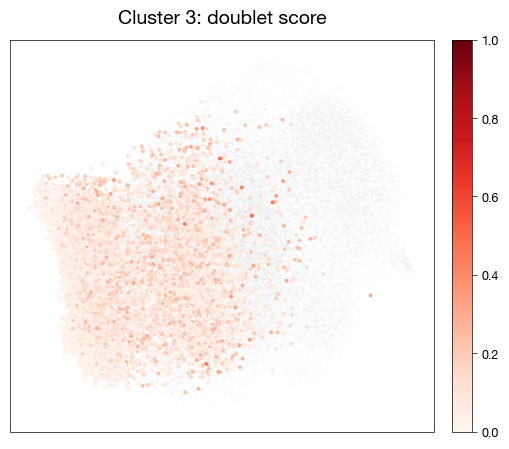

In [ ]:
## A test cluster

fig, ax = plot_cluster_doublets(d2_dz_clustered, cluster="3")


### We define a helper function, in order to loop through the labels and print them

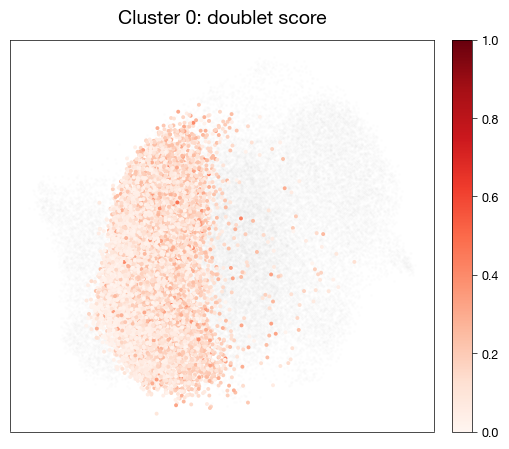

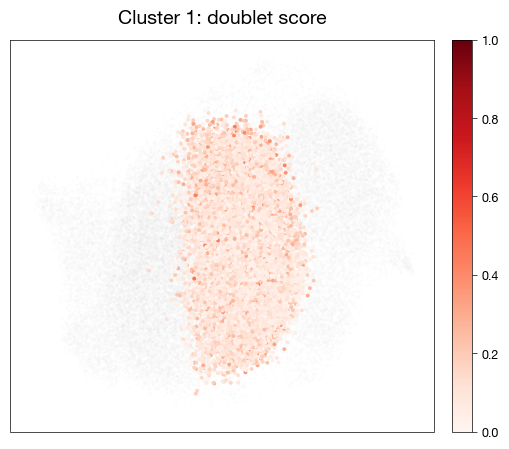

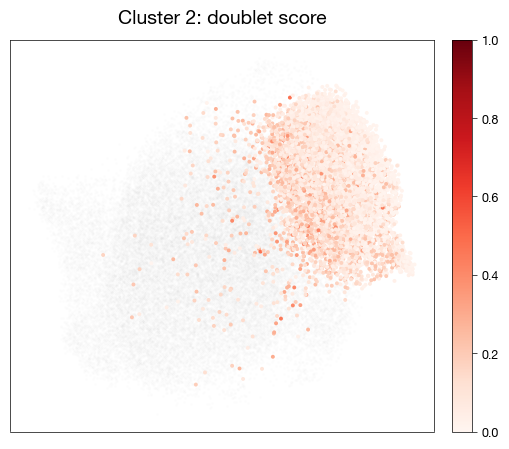

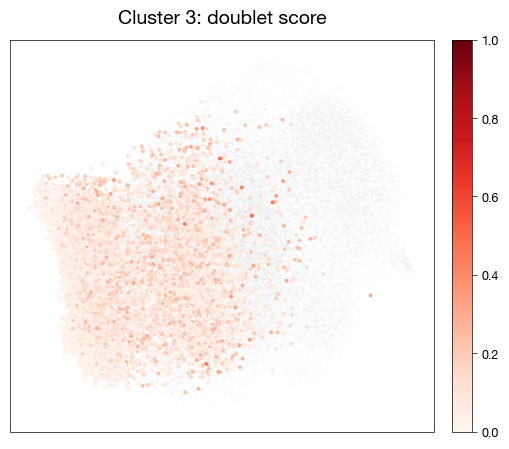

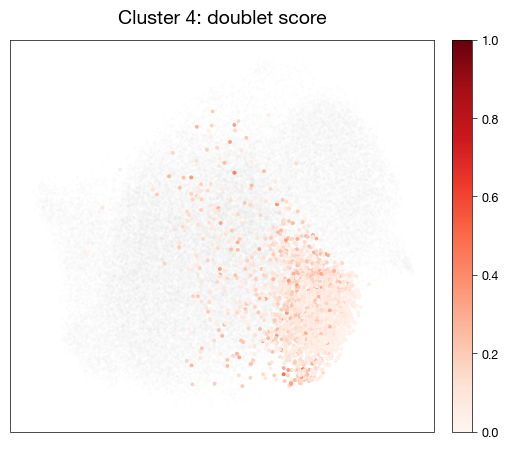

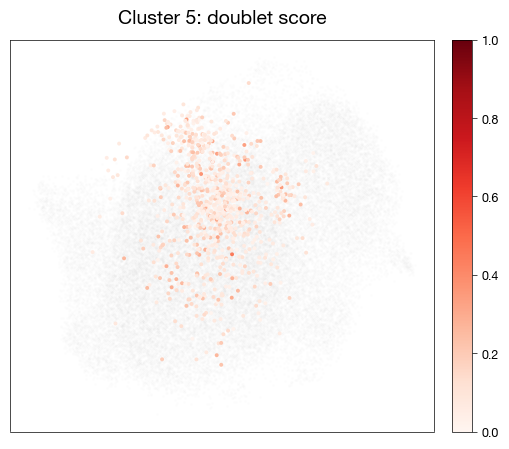

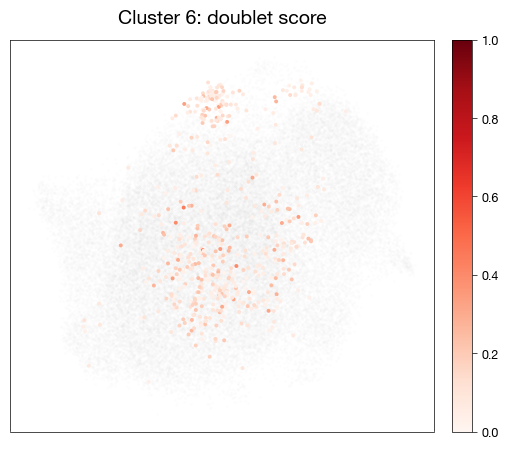

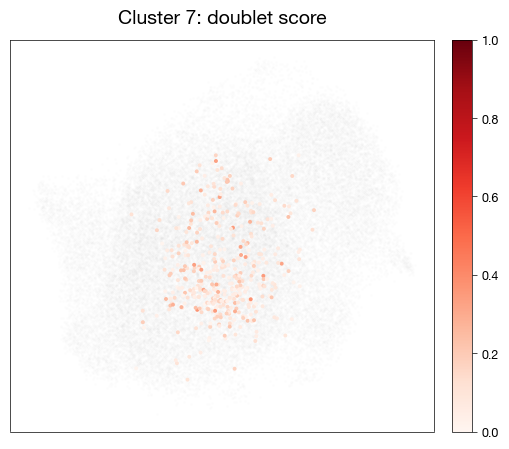

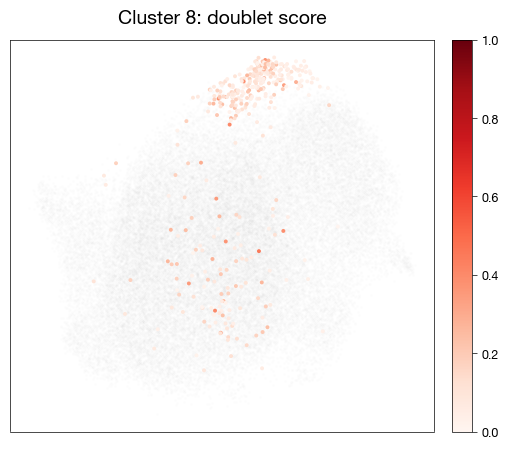

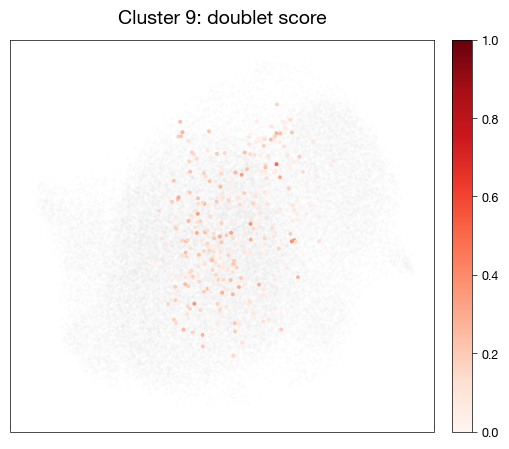

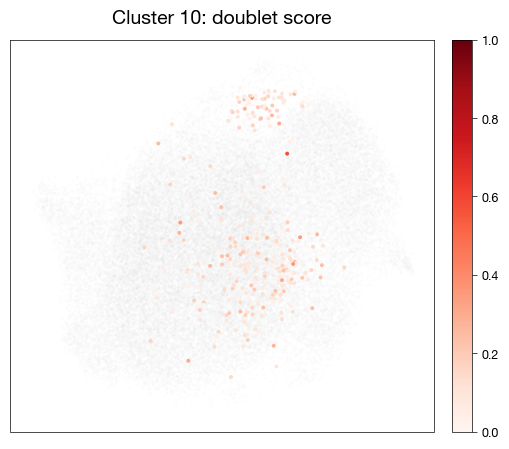

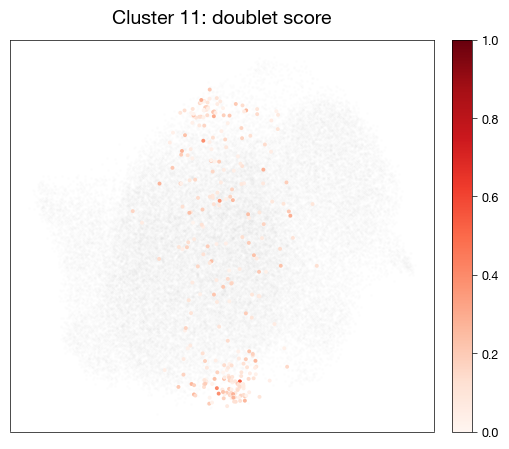

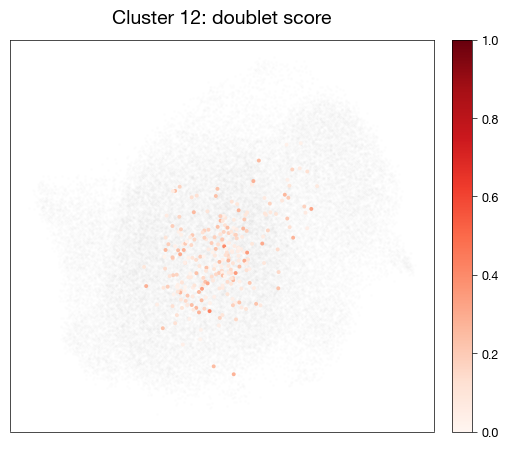

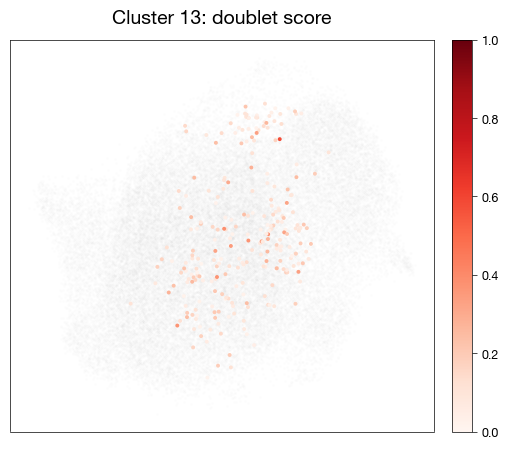

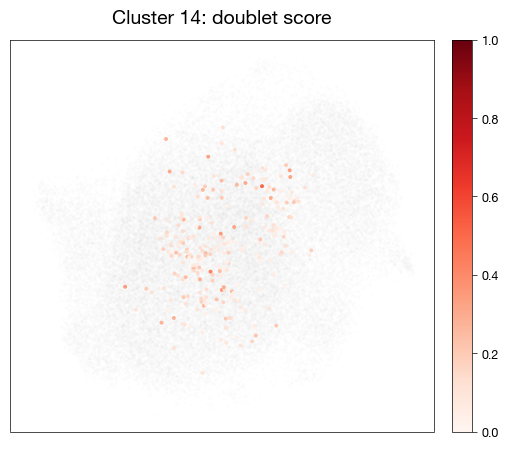

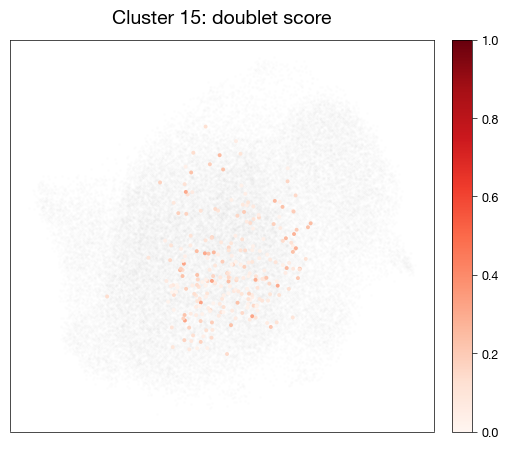

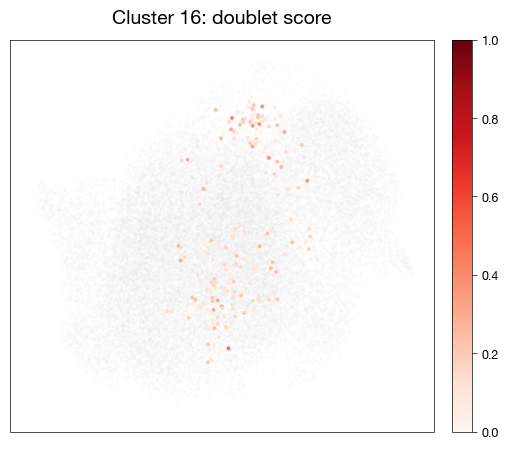

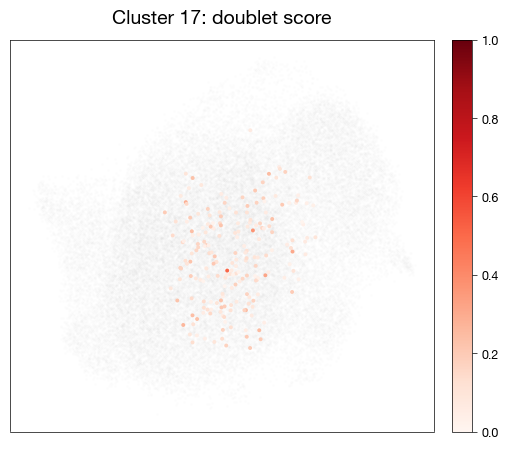

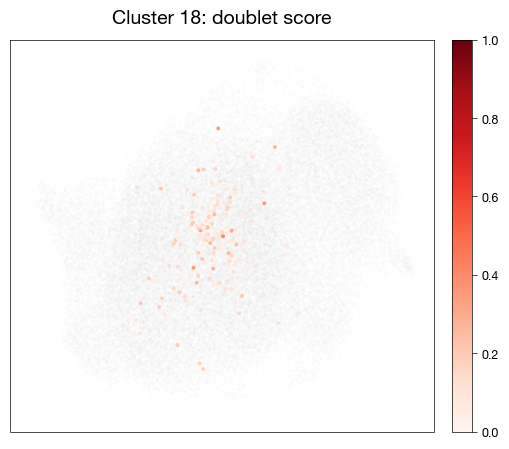

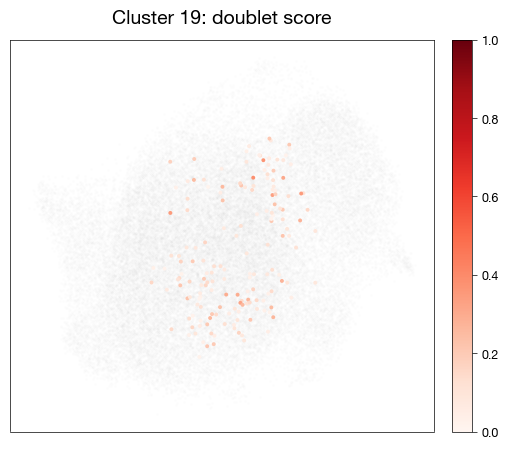

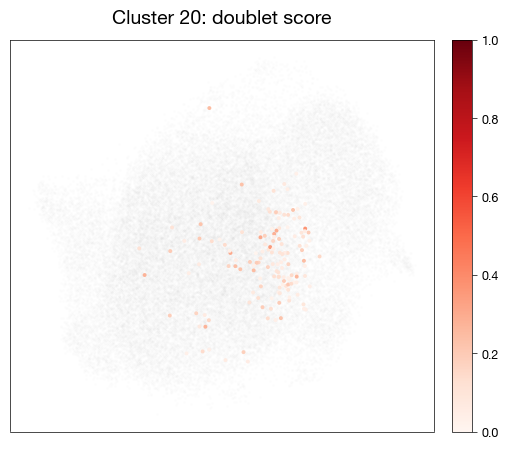

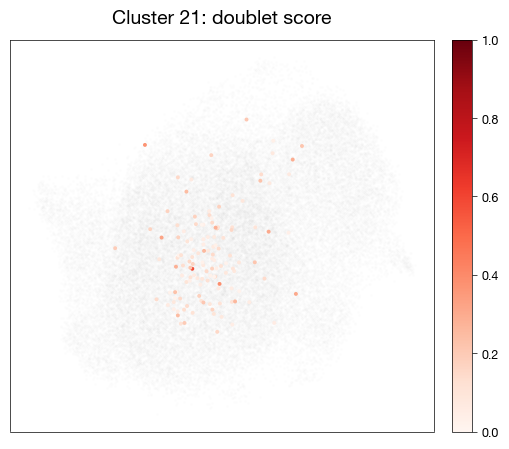

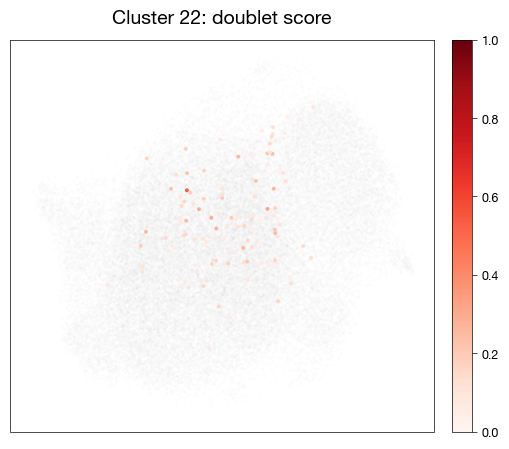

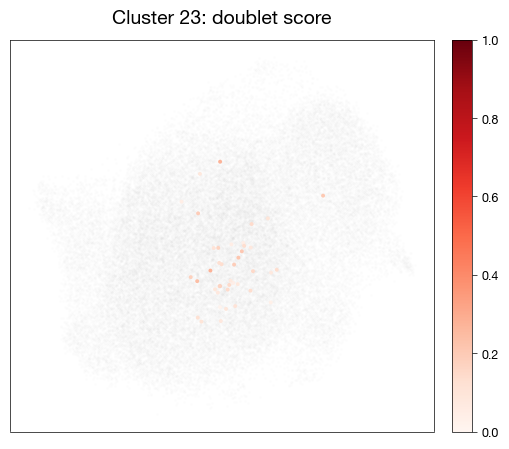

In [ ]:

cluster_key = "leiden"          # we can change this if we want to plot based on different metadata, eg. a cell-type
score_key   = "doublet_score"   # we define from the adata.obs slots

# natural/robust sort (works for '0','1','10' and non-numeric labels). This function creates a list for us to then loop through, for the plotting itself.
def _nsort(vals):
    def _key(v):
        s = str(v)
        try:    return (0, int(s))
        except: return (1, s)
    return sorted(map(str, vals), key=_key)

clusters = _nsort(d2_dz_clustered.obs[cluster_key].unique())

# A loop for plotting, but not yet saving.
for cl in clusters:
    plot_cluster_doublets(d2_dz_clustered, cluster=cl, cluster_key=cluster_key, score_key=score_key)


#### Save the results to the figures/qc subdirectory

In [21]:
os.getcwd()

'/Users/stanleydale/user_generated/breault-lab/single-cell/analysis'

Saving doublet UMAPs to: ../figures/qc/doublet_score_umaps/d2_dz_clustered


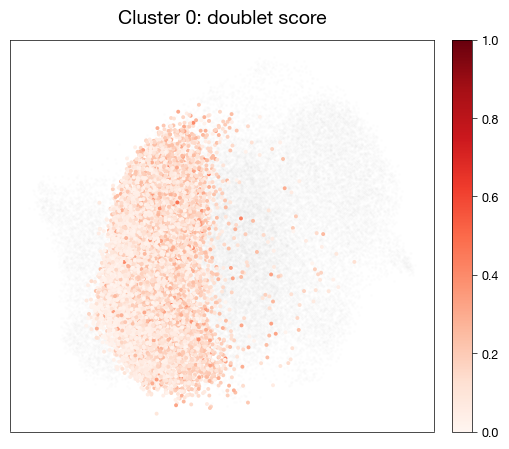

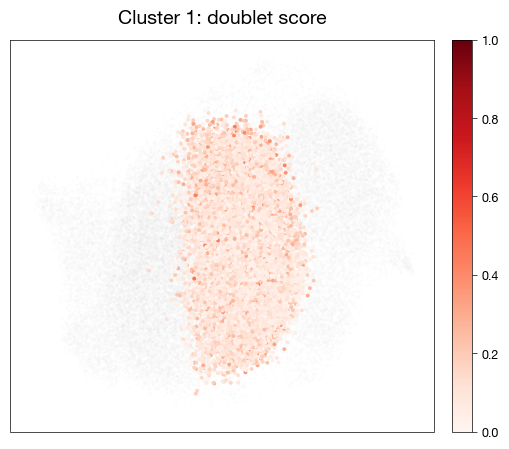

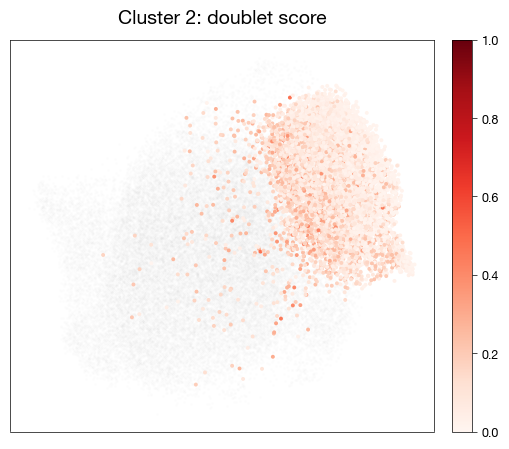

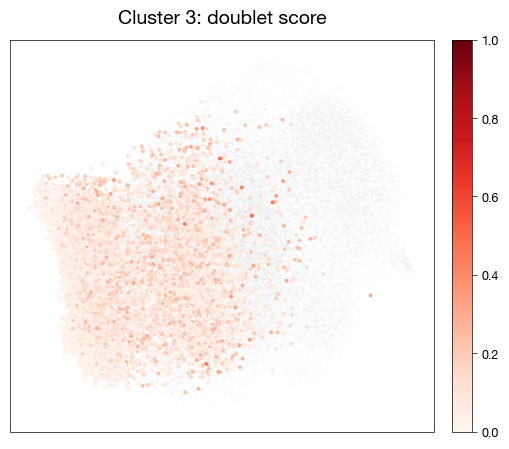

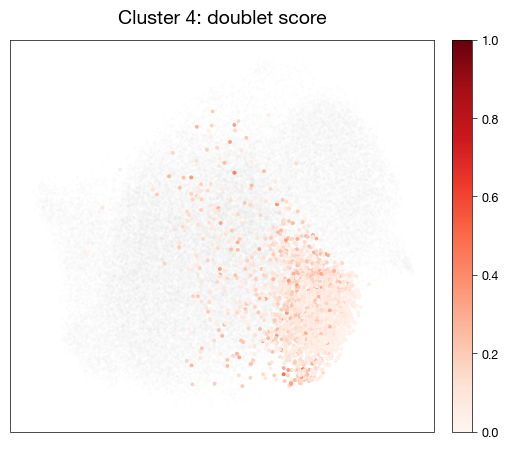

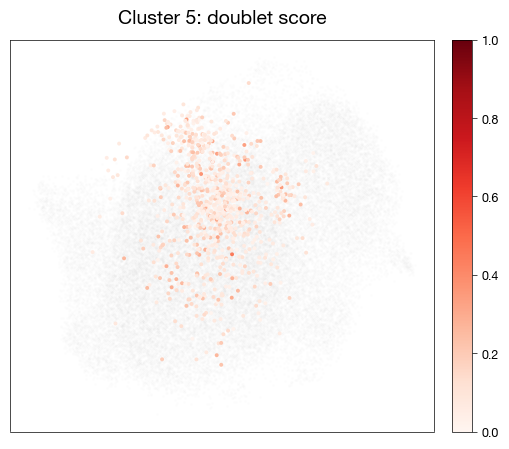

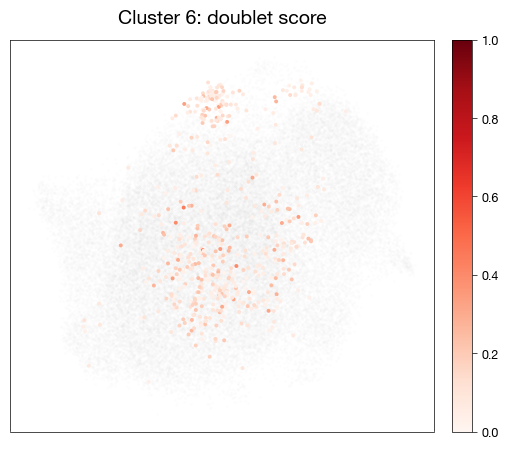

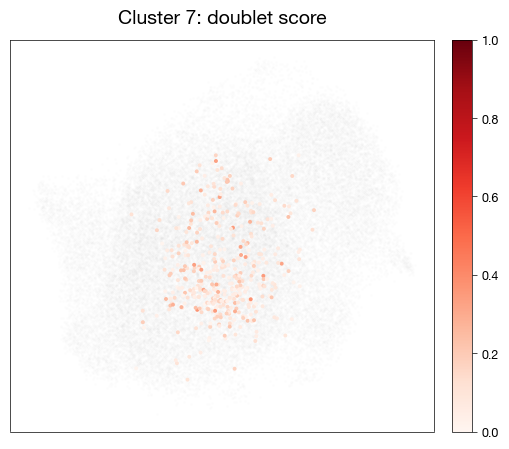

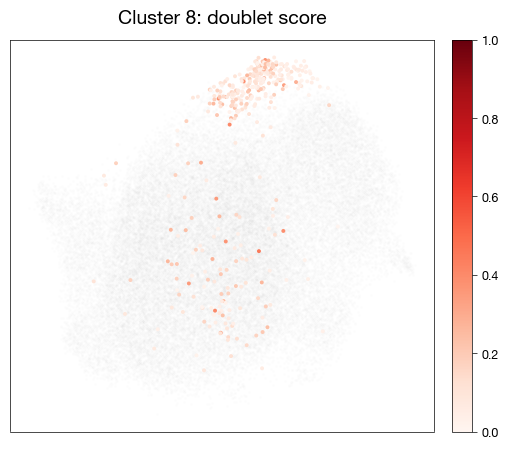

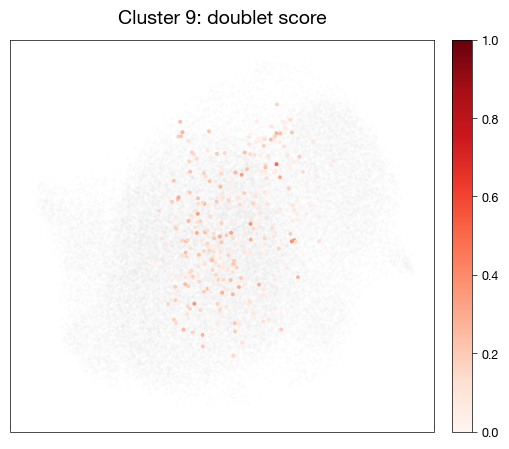

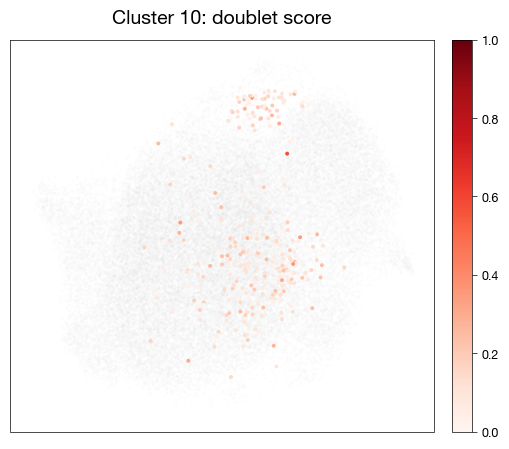

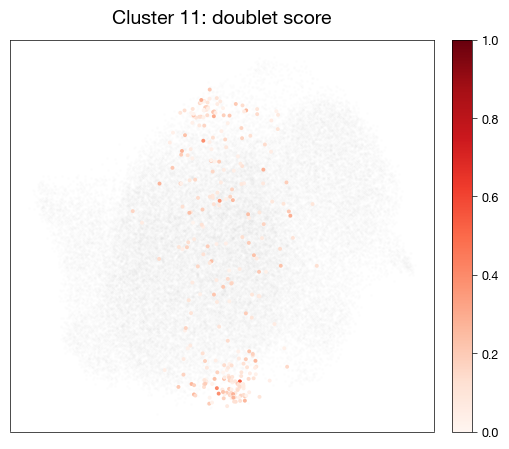

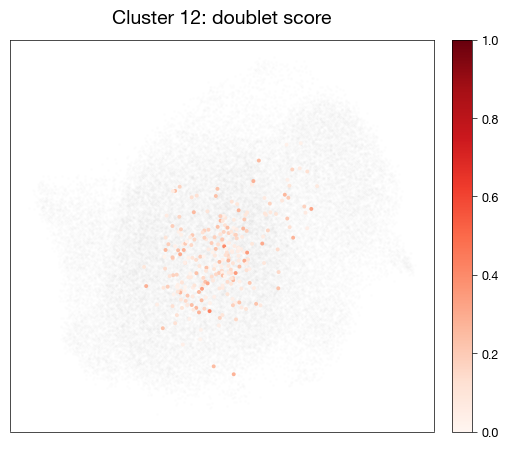

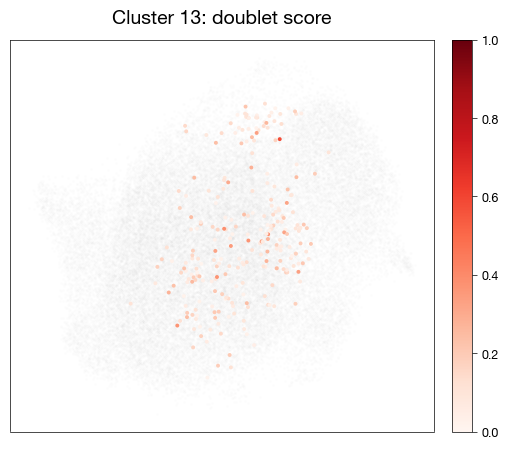

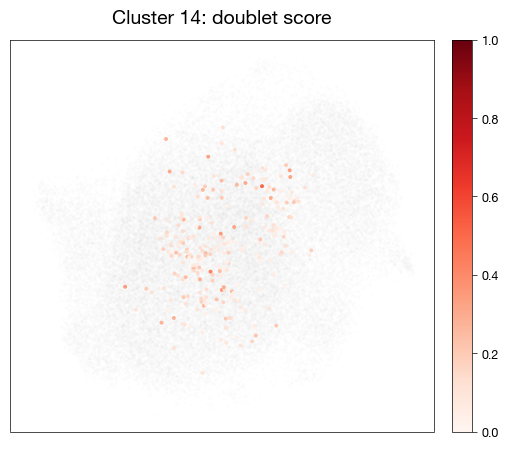

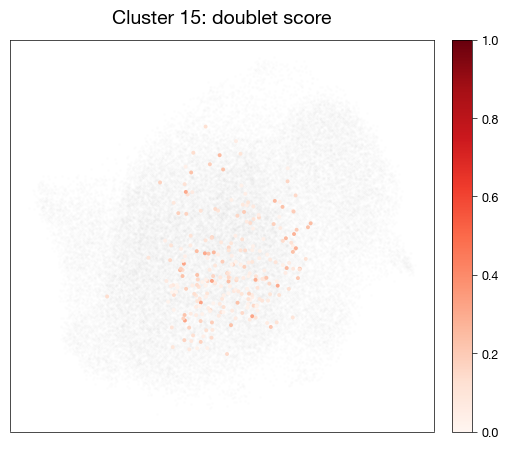

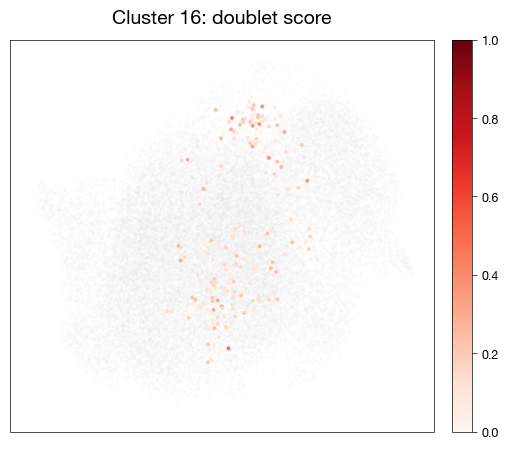

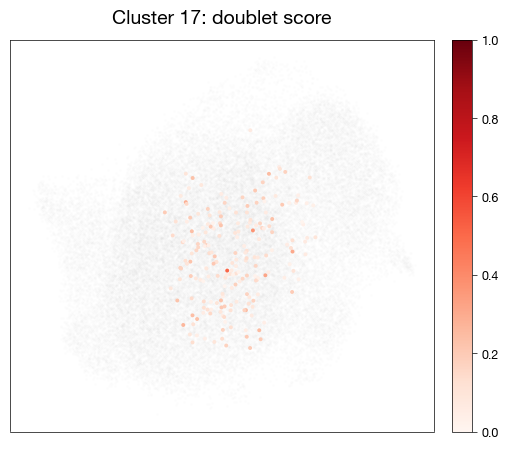

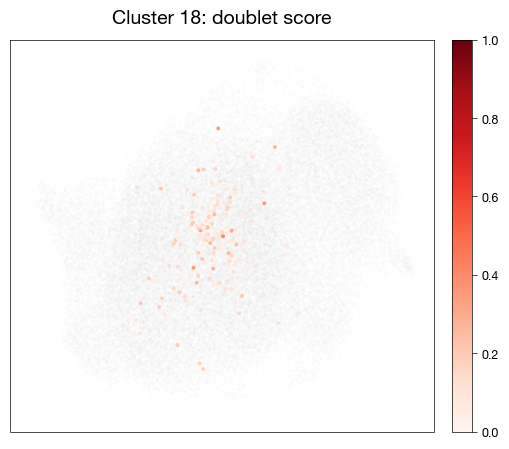

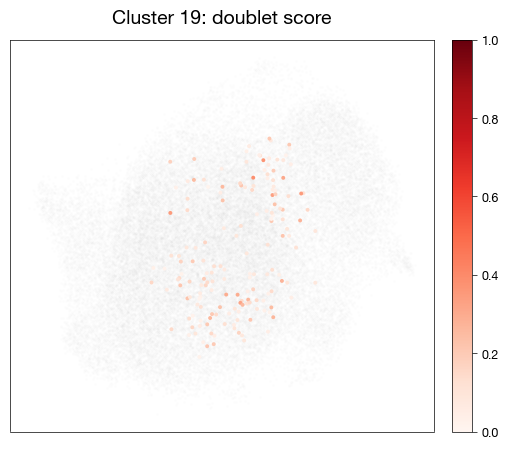

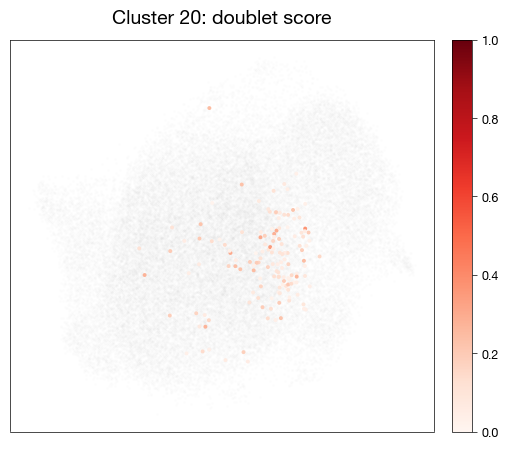

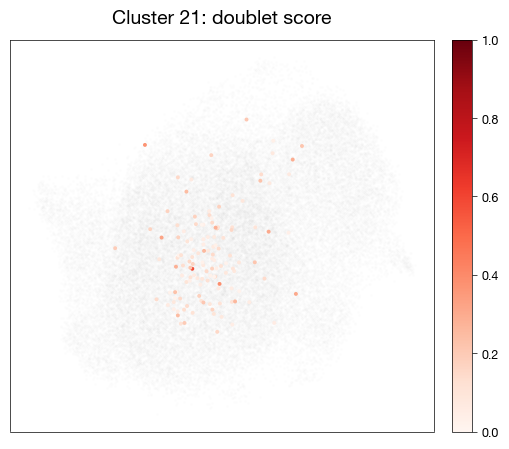

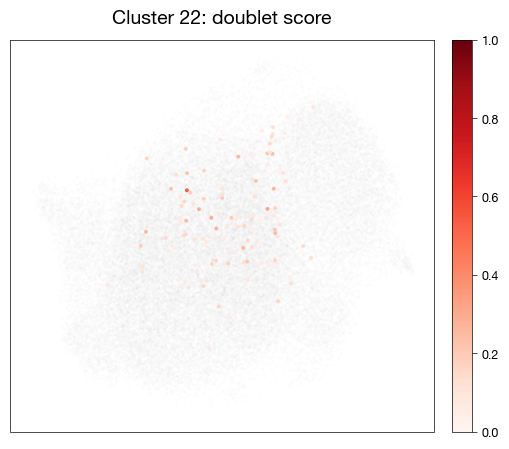

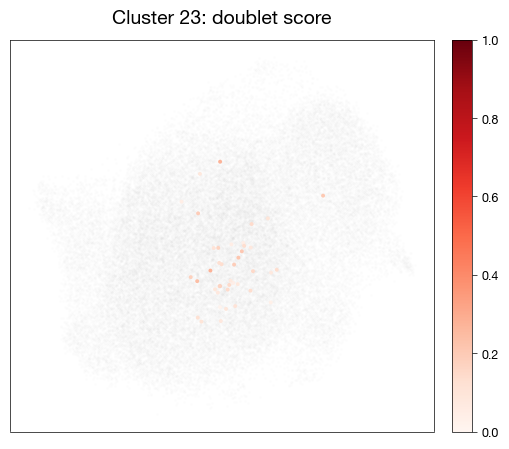

In [14]:
save_doublet_umaps(
    d2_dz_clustered,
    object_name="d2_dz_clustered"
)
